# 00 — krkCMd Baseline: Audit → Benchmark → Robustness

**Tujuan:** baseline kasar yang aman dikembangkan. Jalankan dari atas ke bawah.

> **Validasi Grouping (D-003 APPROVED):** Group key `Series + Image + Gridline` telah terverifikasi secara matematis dan fisik mewakili lokasi retak fisik yang sama persis lintas `Stage` (3.183 kelompok unik, masing-masing tepat 6 observasi Stage 1 sampai 6). Pembagian data berbasis group ini menjamin tidak terjadi data leakage.

## 0. Setup dan lokasi file

Letakkan CSV di `data/raw/krkCMd_table.csv`. Notebook ini memakai path relatif dari root proyek.

Jika notebook dibuka dari subfolder `notebooks/`, fungsi pencari di bawah akan mencoba root saat ini dan parent folder.

In [1]:
from pathlib import Path
import os, sys, json, platform, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

def find_project_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    for candidate in candidates:
        if (candidate / "AGENT.md").exists() and (candidate / "data").exists():
            return candidate
    # Common notebook launch case: current folder is notebooks/
    if here.name == "notebooks" and (here.parent / "data").exists():
        return here.parent
    return here

ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "raw" / "krkCMd_table.csv"
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
LOGS = REPORTS / "logs"
for folder in [TABLES, FIGURES, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("CSV exists:", DATA_PATH.exists())
print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {DATA_PATH}\n"
        "Taruh krkCMd_table.csv ke folder data/raw/."
    )

Project root: C:\PROJECT\krkCMd_research_starter
CSV exists: True
Python: 3.11.9
OS: Windows-10-10.0.26300-SP0


## 1. Baca data dan audit schema

Cell ini tidak mengubah file asli. Ia hanya membaca CSV dan membuat ringkasan.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
display(df.head())
print("\\nColumns:")
print(df.columns.tolist())

audit = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
}
pd.Series(audit).to_csv(TABLES / "initial_audit_summary.csv", header=["value"])
display(pd.Series(audit, name="value").to_frame())

Shape: (19098, 510)


,No,Profile,Series,Image,Gridline,Stage,x1,x2,x3,x4,...,x495,x496,x497,x498,x499,x500,x501,MANwidth,DLMwidth,AEDwidth
0,1,CMd_0.28_2mths_Image6_Gridline1786-1400_Stage1,CMd_0.28_2mths,6,1786-1400,1,177.67,177.67,177.67,177.67,...,173.67,174.67,175.67,178.33,179.00,181.00,182.00,408.7812,421.5143,392.9062
1,2,CMd_0.28_2mths_Image6_Gridline1786-1400_Stage2,CMd_0.28_2mths,6,1786-1400,2,194.33,194.00,195.00,197.00,...,160.67,162.00,163.33,164.67,167.33,169.00,169.00,254.0000,259.7951,222.2500
2,3,CMd_0.28_2mths_Image6_Gridline1786-1400_Stage3,CMd_0.28_2mths,6,1786-1400,3,203.00,204.00,205.00,204.67,...,181.00,183.67,185.67,188.33,189.00,190.67,192.00,222.2500,229.2490,194.4688
3,4,CMd_0.28_2mths_Image6_Gridline1786-1400_Stage4,CMd_0.28_2mths,6,1786-1400,4,192.33,189.33,193.67,192.67,...,182.00,180.33,184.33,185.00,186.00,189.33,190.67,250.0312,247.1682,214.3125
4,5,CMd_0.28_2mths_Image6_Gridline1786-1400_Stage5,CMd_0.28_2mths,6,1786-1400,5,207.33,205.67,206.67,208.67,...,160.67,164.00,163.33,165.67,165.67,169.33,171.33,257.9688,268.4224,226.2188


\nColumns:
['No', 'Profile', 'Series', 'Image', 'Gridline', 'Stage', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39', 'x40', 'x41', 'x42', 'x43', 'x44', 'x45', 'x46', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x53', 'x54', 'x55', 'x56', 'x57', 'x58', 'x59', 'x60', 'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x73', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x80', 'x81', 'x82', 'x83', 'x84', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94', 'x95', 'x96', 'x97', 'x98', 'x99', 'x100', 'x101', 'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x109', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x117', 'x118', 'x119', 'x120', 'x121', 'x122', 'x123', 'x124', 'x125', 'x126', 'x127', 'x128', 'x129', 'x130',

,value
rows,19098
columns,510
missing_cells,0
duplicate_rows,0
python,3.11.9
pandas,2.3.3
numpy,2.4.6


## 2. Validasi kolom utama

Jangan lanjut ke training jika kolom fitur/target tidak cocok. Kita sengaja memeriksa nama kolom, bukan menebaknya.

In [3]:
metadata_candidates = ["No", "Profile", "Series", "Image", "Gridline", "Stage"]
feature_cols = [f"x{i}" for i in range(1, 502)]
target_col = "MANwidth"
baseline_cols = ["DLMwidth", "AEDwidth"]

missing_features = [c for c in feature_cols if c not in df.columns]
missing_metadata = [c for c in metadata_candidates if c not in df.columns]
missing_baselines = [c for c in baseline_cols if c not in df.columns]

print("Missing x features:", len(missing_features), missing_features[:10])
print("Missing metadata:", missing_metadata)
print("Missing comparison baselines:", missing_baselines)
print("Target present:", target_col in df.columns)

if missing_features:
    raise ValueError("Kolom x1..x501 tidak lengkap. Periksa schema CSV sebelum lanjut.")
if target_col not in df.columns:
    raise ValueError("MANwidth tidak ditemukan. Periksa schema CSV sebelum lanjut.")

# Convert model columns to numeric explicitly; invalid strings become NaN and are reported.
for col in feature_cols + [target_col] + [c for c in baseline_cols if c in df.columns]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Rows with missing target:", int(df[target_col].isna().sum()))
print("Rows with any missing profile feature:", int(df[feature_cols].isna().any(axis=1).sum()))
display(df[[target_col] + [c for c in baseline_cols if c in df.columns]].describe().T)

Missing x features: 0 []
Missing metadata: []
Missing comparison baselines: []
Target present: True
Rows with missing target: 0
Rows with any missing profile feature: 0


,count,mean,std,min,25%,50%,75%,max
MANwidth,19098.0,148.875506,141.788580,0.0,0.000000,119.06250,242.093800,813.5938
DLMwidth,19098.0,147.717440,137.147274,0.0,22.802563,117.48725,233.858725,651.5065
AEDwidth,19098.0,125.631158,125.024402,0.0,23.812500,83.34375,198.437500,992.1875


## 3. Metadata dan struktur kelompok

Periksa jumlah kategori dan ukuran grup. Group key tervalidasi (D-003 APPROVED) adalah `Series + Image + Gridline` tanpa Stage agar pengamatan pada lokasi yang sama di stage berbeda tidak bocor ke partisi lain.

**Status grouping:** Tervalidasi konsisten (3.183 kelompok x 6 stages = 19.098 baris) sesuai keputusan D-003.

In [4]:
for col in metadata_candidates:
    if col in df.columns:
        print(f"\\n{col}: {df[col].nunique(dropna=False)} unique values")
        display(df[col].value_counts(dropna=False).head(15).to_frame("count"))

group_cols = ["Series", "Image", "Gridline"]
if all(c in df.columns for c in group_cols):
    group_id = df[group_cols].astype("string").fillna("<NA>").agg("||".join, axis=1)
    group_sizes = group_id.value_counts()
    print("Candidate groups:", group_id.nunique())
    display(group_sizes.describe().to_frame("group_size_stats"))
    group_sizes.to_csv(TABLES / "candidate_group_sizes.csv", header=["rows"])
else:
    group_id = None
    print("Metadata grouping columns incomplete; do not train with random split as a substitute.")

\nNo: 19098 unique values


,count
No,
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


\nProfile: 19098 unique values


,count
Profile,
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage1,1
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage2,1
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage3,1
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage4,1
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage5,1
CMd_0.28_2mths_Image6_Gridline1786-1400_Stage6,1
CMd_0.28_2mths_Image6_Gridline1786-1500_Stage1,1
CMd_0.28_2mths_Image6_Gridline1786-1500_Stage2,1
CMd_0.28_2mths_Image6_Gridline1786-1500_Stage3,1


\nSeries: 4 unique values


,count
Series,
CMd_0.28_2mths,7026
CMd_0.23_20mths,5844
CMd_0.23_2mths,3936
CMd_0.28_20mths,2292


... (4 outputs left out)

\nStage: 6 unique values


,count
Stage,
1,3183
2,3183
3,3183
4,3183
5,3183
6,3183


Candidate groups: 3183


,group_size_stats
count,3183.0
mean,6.0
std,0.0
min,6.0
25%,6.0
50%,6.0
75%,6.0
max,6.0


## 4. Distribusi target dan contoh brightness profile

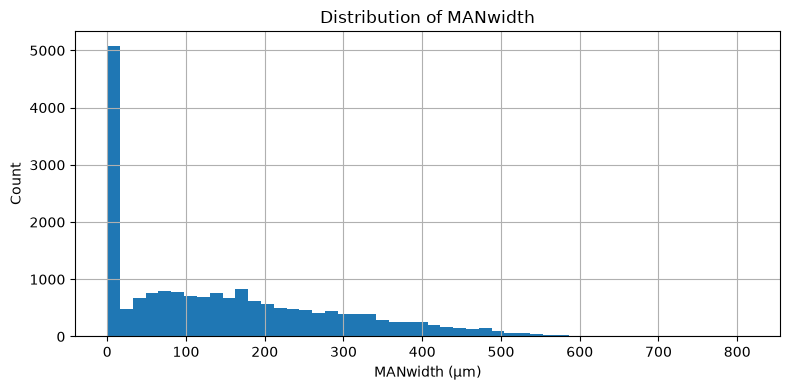

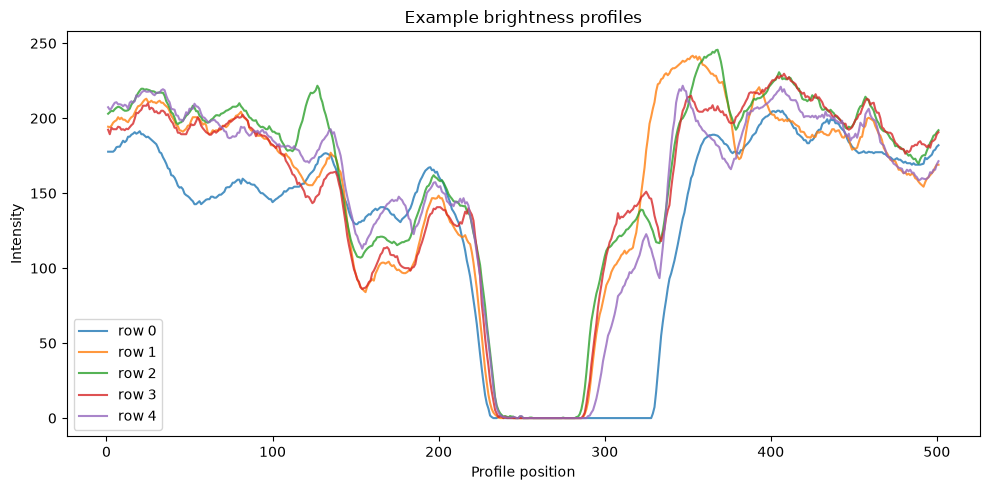

,count,mean,median,std
Series,,,,
CMd_0.23_20mths,5844,130.736492,103.18750,123.457147
CMd_0.23_2mths,3936,242.489012,246.06250,160.105327
CMd_0.28_20mths,2292,163.813100,130.96880,145.352390
CMd_0.28_2mths,7026,106.647305,75.40625,116.985545


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
df[target_col].dropna().hist(bins=50, ax=ax)
ax.set_title("Distribution of MANwidth")
ax.set_xlabel("MANwidth (µm)")
ax.set_ylabel("Count")
fig.tight_layout()
fig.savefig(FIGURES / "manwidth_distribution.png", dpi=160)
plt.show()

valid_profile_rows = df[feature_cols].dropna().index
if len(valid_profile_rows):
    sample_idx = valid_profile_rows[:min(5, len(valid_profile_rows))]
    fig, ax = plt.subplots(figsize=(10, 5))
    x_axis = np.arange(1, 502)
    for idx in sample_idx:
        ax.plot(x_axis, df.loc[idx, feature_cols].astype(float).values, alpha=0.8, label=f"row {idx}")
    ax.set_title("Example brightness profiles")
    ax.set_xlabel("Profile position")
    ax.set_ylabel("Intensity")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / "sample_brightness_profiles.png", dpi=160)
    plt.show()

if "Series" in df.columns:
    display(df.groupby("Series", dropna=False)[target_col].agg(["count","mean","median","std"]).sort_index())

## 5. Siapkan data modeling dan group-aware split

Pembagian data membagi kelompok lokasi fisik (`Series + Image + Gridline`), bukan baris, sesuai keputusan D-003 (APPROVED). Group tidak boleh overlap antara train, validation, dan test.

Notebook memisahkan test lebih dulu, lalu validation dari sisa data. Group tidak boleh overlap.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

required_for_model = feature_cols + [target_col]
model_df = df.dropna(subset=required_for_model).copy()
model_df = model_df.reset_index(names="source_row_id")

if group_id is None:
    raise ValueError("Group metadata tidak tersedia. Hentikan; tentukan split yang valid setelah audit.")
model_df["group_id"] = group_id.loc[model_df["source_row_id"]].astype(str).values

# Split 1: hold out test groups
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(gss_test.split(model_df[feature_cols], model_df[target_col], groups=model_df["group_id"]))
trainval = model_df.iloc[trainval_idx].copy()
test = model_df.iloc[test_idx].copy()

# Split 2: hold out validation groups from remaining trainval
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
train_idx, val_idx = next(gss_val.split(trainval[feature_cols], trainval[target_col], groups=trainval["group_id"]))
train = trainval.iloc[train_idx].copy()
val = trainval.iloc[val_idx].copy()

sets = {"train": train, "validation": val, "test": test}
for name, part in sets.items():
    print(name, "rows=", len(part), "groups=", part["group_id"].nunique())

group_sets = {name: set(part["group_id"]) for name, part in sets.items()}
assert group_sets["train"].isdisjoint(group_sets["validation"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["validation"].isdisjoint(group_sets["test"])

split_manifest = pd.concat([
    part[["source_row_id","group_id"]].assign(split=name)
    for name, part in sets.items()
], ignore_index=True)
split_manifest.to_csv(TABLES / "group_split_manifest.csv", index=False)
print("No group overlap: PASS")

train rows= 12216 groups= 2036
validation rows= 3060 groups= 510
test rows= 3822 groups= 637
No group overlap: PASS


## 6. Benchmark model CPU-friendly

Model-model comparison memakai test set yang sama. Hyperparameter di bawah sengaja sederhana sebagai baseline kasar; ini belum merupakan hyperparameter search final.

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
import joblib, time

X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
X_test, y_test = test[feature_cols], test[target_col]

models = {
    "Dummy_mean": DummyRegressor(strategy="mean"),
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "RandomForest": RandomForestRegressor(n_estimators=250, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=250, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=SEED),
    "SVR_RBF": make_pipeline(StandardScaler(), SVR(C=10.0, epsilon=0.1, kernel="rbf")),
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE_um": mean_absolute_error(y_true, y_pred),
        "RMSE_um": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "MedianAE_um": median_absolute_error(y_true, y_pred),
        "Bias_um": float(np.mean(np.asarray(y_pred) - np.asarray(y_true))),
        "n_test": int(len(y_true)),
    }

results, prediction_frames = [], []
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    elapsed = time.time() - start
    row = {"model": name, **regression_metrics(y_test, pred), "fit_predict_seconds": elapsed}
    results.append(row)
    prediction_frames.append(pd.DataFrame({
        "source_row_id": test["source_row_id"].values,
        "group_id": test["group_id"].values,
        "y_true_MANwidth_um": y_test.values,
        "y_pred_um": pred,
        "model": name,
    }))
    joblib.dump(model, ROOT / "artifacts" / "models" / f"{name}.joblib")
    print(name, "MAE:", round(row["MAE_um"], 3), "seconds:", round(elapsed, 1))

metrics_df = pd.DataFrame(results).sort_values("MAE_um")
predictions_df = pd.concat(prediction_frames, ignore_index=True)
metrics_df.to_csv(TABLES / "benchmark_metrics.csv", index=False)
predictions_df.to_csv(ROOT / "artifacts" / "results" / "benchmark_predictions.csv", index=False)
display(metrics_df)

Dummy_mean MAE: 116.599 seconds: 0.0
LinearRegression MAE: 49.827 seconds: 0.4
RandomForest MAE: 14.407 seconds: 103.0
ExtraTrees MAE: 14.312 seconds: 37.6
HistGradientBoosting MAE: 15.15 seconds: 3.9
SVR_RBF MAE: 28.119 seconds: 47.4


,model,MAE_um,RMSE_um,R2,MedianAE_um,Bias_um,n_test,fit_predict_seconds
3,ExtraTrees,14.311523,35.504987,0.935147,5.623690,1.212636,3822,37.556074
2,RandomForest,14.407363,35.336657,0.935760,5.602031,0.901033,3822,102.991113
4,HistGradientBoosting,15.149774,36.794280,0.930351,6.457064,1.158559,3822,3.864634
5,SVR_RBF,28.118558,44.778006,0.896847,17.136260,4.641504,3822,47.366307
1,LinearRegression,49.826529,66.898135,0.769760,39.113908,-0.117477,3822,0.411904
0,Dummy_mean,116.599211,139.595829,-0.002531,119.416945,-7.014014,3822,0.000000


## 7. Bandingkan DLMwidth dan AEDwidth sebagai baseline lama

Baseline ini dihitung pada baris test yang sama dan hanya jika nilai prediksinya tersedia. Jangan masukkan kolom ini ke X.

In [8]:
baseline_results = []
for col in baseline_cols:
    if col in test.columns:
        valid = test[col].notna() & test[target_col].notna()
        if valid.sum():
            baseline_results.append({
                "model": col,
                **regression_metrics(test.loc[valid, target_col], test.loc[valid, col]),
                "n_test": int(valid.sum())
            })
baseline_df = pd.DataFrame(baseline_results)
if len(baseline_df):
    baseline_df.to_csv(TABLES / "existing_baseline_metrics.csv", index=False)
    display(baseline_df)
else:
    print("DLMwidth/AEDwidth tidak tersedia atau tidak memiliki nilai valid pada test set.")

,model,MAE_um,RMSE_um,R2,MedianAE_um,Bias_um,n_test
0,DLMwidth,13.635201,28.781404,0.957384,6.4420,-0.921287,3822
1,AEDwidth,35.979388,66.504550,0.772461,23.8125,-22.384705,3822


## 8. Ide 2 — Synthetic robustness stress test

Pilih model dengan MAE validation terendah (bukan test). Fit-nya sudah dilakukan pada train; validation hanya dipakai untuk memilih model. Uji gangguan hanya pada test features.

In [12]:
# Select best model by validation MAE, refit on train+validation, then evaluate test perturbations.
val_scores = []
for name, model in models.items():
    pv = model.predict(X_val)
    val_scores.append((name, mean_absolute_error(y_val, pv)))
best_name = sorted(val_scores, key=lambda z: z[1])[0][0]
print("Best model by validation MAE:", best_name)

# Refit selected model on train + validation only
trainval_full = pd.concat([train, val], ignore_index=True)
best_model = models[best_name]
best_model.fit(trainval_full[feature_cols], trainval_full[target_col])

X_clean = X_test.to_numpy(dtype=float)
y_clean = y_test.to_numpy(dtype=float)
rng = np.random.default_rng(SEED)

def perturb_profiles(X, kind, amount):
    Z = X.copy().astype(float)
    if kind == "brightness_shift":
        Z = Z + amount
    elif kind == "contrast_scale":
        means = Z.mean(axis=1, keepdims=True)
        Z = means + amount * (Z - means)
    elif kind == "gaussian_noise":
        Z = Z + rng.normal(0, amount, size=Z.shape)
    elif kind == "gaussian_smoothing":
        from scipy.ndimage import gaussian_filter1d
        Z = gaussian_filter1d(Z, sigma=amount, axis=1)
    else:
        raise ValueError(kind)
    return np.clip(Z, 0, 255)

perturbation_specs = [
    ("clean", None, None),
    ("brightness_shift_-20", "brightness_shift", -20),
    ("brightness_shift_+20", "brightness_shift", 20),
    ("contrast_scale_0.8", "contrast_scale", 0.8),
    ("contrast_scale_1.2", "contrast_scale", 1.2),
    ("gaussian_noise_sigma5", "gaussian_noise", 5),
    ("gaussian_noise_sigma10", "gaussian_noise", 10),
    ("gaussian_smoothing_sigma1", "gaussian_smoothing", 1.0),
]

robust_rows = []
for label, kind, amount in perturbation_specs:
    Xp = X_clean if kind is None else perturb_profiles(X_clean, kind, amount)
    yp = best_model.predict(Xp)
    robust_rows.append({"condition": label, "selected_model": best_name, **regression_metrics(y_clean, yp)})

robust_df = pd.DataFrame(robust_rows)
clean_mae = robust_df.loc[robust_df["condition"] == "clean", "MAE_um"].iloc[0]
robust_df["MAE_delta_um_vs_clean"] = robust_df["MAE_um"] - clean_mae
robust_df["MAE_increase_percent_vs_clean"] = np.where(clean_mae > 0, 100 * robust_df["MAE_delta_um_vs_clean"] / clean_mae, np.nan)
robust_df.to_csv(TABLES / "robustness_metrics.csv", index=False)
display(robust_df)

Best model by validation MAE: ExtraTrees


c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, b

,condition,selected_model,MAE_um,RMSE_um,R2,MedianAE_um,Bias_um,n_test,MAE_delta_um_vs_clean,MAE_increase_percent_vs_clean
0,clean,ExtraTrees,14.047211,36.127368,0.932853,5.664757,0.941977,3822,0.000000,0.000000
1,brightness_shift_-20,ExtraTrees,25.319835,46.282552,0.889799,15.539009,21.255413,3822,11.272624,80.248125
2,brightness_shift_+20,ExtraTrees,51.899147,85.225669,0.626325,27.225602,-48.335549,3822,37.851936,269.462277
3,contrast_scale_0.8,ExtraTrees,77.144320,112.518250,0.348673,48.323476,-74.691767,3822,63.097109,449.178896
4,contrast_scale_1.2,ExtraTrees,25.992077,46.717792,0.887716,16.168688,22.173805,3822,11.944866,85.033715
5,gaussian_noise_sigma5,ExtraTrees,15.246616,36.500132,0.931460,6.765395,-1.882981,3822,1.199405,8.538385
6,gaussian_noise_sigma10,ExtraTrees,19.276669,38.867861,0.922280,9.970850,-7.336280,3822,5.229457,37.227725
7,gaussian_smoothing_sigma1,ExtraTrees,14.085716,36.100049,0.932955,5.834040,0.057706,3822,0.038504,0.274107


## 9. Visualisasi hasil

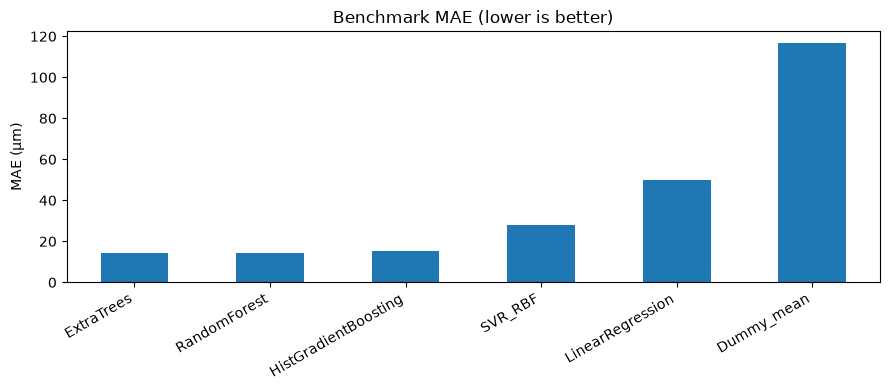

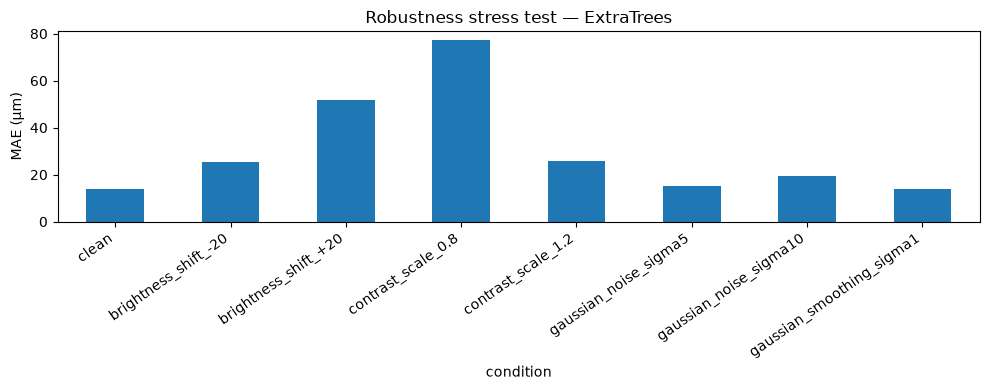

In [10]:
if "metrics_df" in globals() and len(metrics_df):
    fig, ax = plt.subplots(figsize=(9, 4))
    metrics_df.sort_values("MAE_um").plot.bar(x="model", y="MAE_um", ax=ax, legend=False)
    ax.set_title("Benchmark MAE (lower is better)")
    ax.set_ylabel("MAE (µm)")
    ax.set_xlabel("")
    plt.xticks(rotation=30, ha="right")
    fig.tight_layout()
    fig.savefig(FIGURES / "benchmark_mae.png", dpi=160)
    plt.show()

if "robust_df" in globals() and len(robust_df):
    fig, ax = plt.subplots(figsize=(10, 4))
    robust_df.plot.bar(x="condition", y="MAE_um", ax=ax, legend=False)
    ax.set_title(f"Robustness stress test — {best_name}")
    ax.set_ylabel("MAE (µm)")
    plt.xticks(rotation=35, ha="right")
    fig.tight_layout()
    fig.savefig(FIGURES / "robustness_mae.png", dpi=160)
    plt.show()

## 10. Ide 4 gate — jangan otomatis lanjut

Cell ini membuat ringkasan awal target per-Series. Perbedaan distribusi bukan otomatis bukti data drift; perlu dilihat bersama distribusi fitur dan performa pada split antar-Series.

**Keputusan:** setelah membaca tabel ini, diskusikan apakah Ide 4 layak. Jangan langsung fine-tuning.

In [13]:
if "Series" in test.columns:
    per_series_rows = []
    for series_value, part in test.groupby("Series", dropna=False):
        # Reconstruct row-aligned predictions for selected model on the test rows in this Series.
        idx = part.index
        # test index may be original reset indices; use explicit row positions for robust alignment
        mask = test["Series"].isna() if pd.isna(series_value) else (test["Series"] == series_value)
        pos = np.flatnonzero(mask.to_numpy())
        if len(pos):
            pred = best_model.predict(X_clean[pos])
            per_series_rows.append({
                "Series": str(series_value),
                "n": len(pos),
                "MAE_um": mean_absolute_error(test.iloc[pos][target_col], pred),
                "RMSE_um": mean_squared_error(test.iloc[pos][target_col], pred) ** 0.5,
                "target_mean_um": test.iloc[pos][target_col].mean(),
                "target_std_um": test.iloc[pos][target_col].std(),
            })
    per_series_df = pd.DataFrame(per_series_rows)
    per_series_df.to_csv(TABLES / "test_per_series_metrics.csv", index=False)
    display(per_series_df)
else:
    print("Kolom Series tidak tersedia.")

print("\\nNEXT: Periksa group key terhadap data descriptor/scripts, review tabel dan grafik, lalu catat keputusan di docs/DECISIONS.md. Ide 4 hanya dijalankan setelah ada persetujuan.")

c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\PROJECT\krkCMd_research_starter\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


,Series,n,MAE_um,RMSE_um,target_mean_um,target_std_um
0,CMd_0.23_20mths,1308,7.261781,13.791389,137.452862,130.078439
1,CMd_0.23_2mths,780,13.142956,24.786004,233.413382,149.067174
2,CMd_0.28_20mths,402,37.731239,74.899459,178.366683,124.919670
3,CMd_0.28_2mths,1332,14.092019,38.800112,117.000657,126.412090


\nNEXT: Periksa group key terhadap data descriptor/scripts, review tabel dan grafik, lalu catat keputusan di docs/DECISIONS.md. Ide 4 hanya dijalankan setelah ada persetujuan.


## 11. Simpan ringkasan run

Cell ini hanya mencatat metadata run. Hasil belum final sampai group key diverifikasi.

In [14]:
run_summary = {
    "seed": SEED,
    "csv_path": str(DATA_PATH.relative_to(ROOT)),
    "dataset_shape": list(df.shape),
    "model_rows_after_dropna": int(len(model_df)),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "train_groups": int(train["group_id"].nunique()),
    "validation_groups": int(val["group_id"].nunique()),
    "test_groups": int(test["group_id"].nunique()),
    "validated_group_columns": group_cols,
    "group_key_verified_against_scripts": True,
    "decision_reference": "D-003 APPROVED",
    "selected_model_by_validation_mae": best_name,
    "status": "Benchmark baseline with validated grouping."
}
with open(LOGS / "baseline_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2)
print(json.dumps(run_summary, indent=2))

{
  "seed": 42,
  "csv_path": "data\\raw\\krkCMd_table.csv",
  "dataset_shape": [
    19098,
    510
  ],
  "model_rows_after_dropna": 19098,
  "train_rows": 12216,
  "validation_rows": 3060,
  "test_rows": 3822,
  "train_groups": 2036,
  "validation_groups": 510,
  "test_groups": 637,
  "validated_group_columns": [
    "Series",
    "Image",
    "Gridline"
  ],
  "group_key_verified_against_scripts": true,
  "decision_reference": "D-003 APPROVED",
  "selected_model_by_validation_mae": "ExtraTrees",
  "status": "Benchmark baseline with validated grouping."
}
